<a href="https://colab.research.google.com/github/Guilherme-Prad/Simulador-de-decisoes/blob/main/%5BNome_1_e_Nome_2%5D_Projeto_A3_Matem%C3%A1tica_Computacional_P2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise de Vendas de uma Loja (Superstore)
Dataset: *Superstore Dataset* (Kaggle)
- **Link Download usando kagglehub**: vivek468/superstore-dataset-final

Neste notebook você vai usar conhecimentos sobre: `rename`, `drop`, `apply`, `lambda`, novas colunas, `groupby`, `sort_values` e também **soma**, **média** e **porcentagem**.

1. Roberto marinho dos santos silva 1012522489
2. Luis Filipe da Silva Rocha 1012522594

## 1. Baixar e carregar os dados

Seção 1: Item 1 ao 4 = 6 pontos (1,5 ponto cada); Item 5 = 4 pontos

In [4]:
import os
import pandas as pd
import kagglehub as kh
import matplotlib.pyplot as plt

In [5]:
path = kh.dataset_download('vivek468/superstore-dataset-final')

Using Colab cache for faster access to the 'superstore-dataset-final' dataset.


In [6]:
arquivos = [arquivo for arquivo in os.listdir(path) if arquivo.endswith('.csv')]
pathJoin = os.path.join(path, arquivos[0])


In [7]:
df = pd.read_csv(pathJoin, encoding='windows-1252')

## 2. Conhecer as colunas

In [8]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

## 3. Remover colunas que não vamos usar (`drop`)

In [10]:
df = df[['Order Date', 'Segment', 'State', 'Region',
         'Category', 'Sub-Category', 'Sales',
         'Quantity', 'Discount', 'Profit']].copy()

df

,Order Date,Segment,State,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,11/8/2016,Consumer,Kentucky,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,11/8/2016,Consumer,Kentucky,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,6/12/2016,Corporate,California,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,10/11/2015,Consumer,Florida,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,10/11/2015,Consumer,Florida,South,Office Supplies,Storage,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...
9989,1/21/2014,Consumer,Florida,South,Furniture,Furnishings,25.2480,3,0.20,4.1028
9990,2/26/2017,Consumer,California,West,Furniture,Furnishings,91.9600,2,0.00,15.6332
9991,2/26/2017,Consumer,California,West,Technology,Phones,258.5760,2,0.20,19.3932
9992,2/26/2017,Consumer,California,West,Office Supplies,Paper,29.6000,4,0.00,13.3200


Manter apenas estas colunas para começar:
- **Order Date:** data_pedido
- **Segment:** segmento
- **State:** Estado
- **Region:** região
- **Category:** categoria
- **Sub-Category:** subcategoria
- **Sales:** vendas
- **Quantity:** quantidade
- **Discount:** desconto
- **Profit:** lucro


In [11]:
# Manter no dataset as colunas citadas acima e exlcuir as demais

## 4. Renomear colunas (`rename`)

In [12]:
df.rename(columns={
    'Order Date': 'data_pedido',
    'Segment': 'segmento',
    'State': 'estado',
    'Region': 'regiao',
    'Category': 'categoria',
    'Sub-Category': 'subcategoria',
    'Sales': 'vendas',
    'Quantity': 'quantidade',
    'Discount': 'desconto',
    'Profit': 'lucro'
}, inplace=True)

In [13]:
df

,data_pedido,segmento,estado,regiao,categoria,subcategoria,vendas,quantidade,desconto,lucro
0,11/8/2016,Consumer,Kentucky,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,11/8/2016,Consumer,Kentucky,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,6/12/2016,Corporate,California,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,10/11/2015,Consumer,Florida,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,10/11/2015,Consumer,Florida,South,Office Supplies,Storage,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...
9989,1/21/2014,Consumer,Florida,South,Furniture,Furnishings,25.2480,3,0.20,4.1028
9990,2/26/2017,Consumer,California,West,Furniture,Furnishings,91.9600,2,0.00,15.6332
9991,2/26/2017,Consumer,California,West,Technology,Phones,258.5760,2,0.20,19.3932
9992,2/26/2017,Consumer,California,West,Office Supplies,Paper,29.6000,4,0.00,13.3200


Visualizar dataset

In [14]:
# Visualizar dataset com as colunas renomeadas

## 5. Criar novas colunas (`apply` e `lambda`)

In [15]:
df['ano'] = df['data_pedido'].astype(str).apply(
    lambda x: x.split('/')[-1]
)

In [16]:
df

,data_pedido,segmento,estado,regiao,categoria,subcategoria,vendas,quantidade,desconto,lucro,ano
0,11/8/2016,Consumer,Kentucky,South,Furniture,Bookcases,261.9600,2,0.00,41.9136,2016
1,11/8/2016,Consumer,Kentucky,South,Furniture,Chairs,731.9400,3,0.00,219.5820,2016
2,6/12/2016,Corporate,California,West,Office Supplies,Labels,14.6200,2,0.00,6.8714,2016
3,10/11/2015,Consumer,Florida,South,Furniture,Tables,957.5775,5,0.45,-383.0310,2015
4,10/11/2015,Consumer,Florida,South,Office Supplies,Storage,22.3680,2,0.20,2.5164,2015
...,...,...,...,...,...,...,...,...,...,...,...
9989,1/21/2014,Consumer,Florida,South,Furniture,Furnishings,25.2480,3,0.20,4.1028,2014
9990,2/26/2017,Consumer,California,West,Furniture,Furnishings,91.9600,2,0.00,15.6332,2017
9991,2/26/2017,Consumer,California,West,Technology,Phones,258.5760,2,0.20,19.3932,2017
9992,2/26/2017,Consumer,California,West,Office Supplies,Paper,29.6000,4,0.00,13.3200,2017


**Ano do pedido** (a data está no formato mês/dia/ano, então pegue a última parte da string):

In [17]:
df['situacao'] = df['lucro'].apply(
    lambda x: 'Lucro' if x > 0 else 'Prejuízo'
)

In [18]:
df

,data_pedido,segmento,estado,regiao,categoria,subcategoria,vendas,quantidade,desconto,lucro,ano,situacao
0,11/8/2016,Consumer,Kentucky,South,Furniture,Bookcases,261.9600,2,0.00,41.9136,2016,Lucro
1,11/8/2016,Consumer,Kentucky,South,Furniture,Chairs,731.9400,3,0.00,219.5820,2016,Lucro
2,6/12/2016,Corporate,California,West,Office Supplies,Labels,14.6200,2,0.00,6.8714,2016,Lucro
3,10/11/2015,Consumer,Florida,South,Furniture,Tables,957.5775,5,0.45,-383.0310,2015,Prejuízo
4,10/11/2015,Consumer,Florida,South,Office Supplies,Storage,22.3680,2,0.20,2.5164,2015,Lucro
...,...,...,...,...,...,...,...,...,...,...,...,...
9989,1/21/2014,Consumer,Florida,South,Furniture,Furnishings,25.2480,3,0.20,4.1028,2014,Lucro
9990,2/26/2017,Consumer,California,West,Furniture,Furnishings,91.9600,2,0.00,15.6332,2017,Lucro
9991,2/26/2017,Consumer,California,West,Technology,Phones,258.5760,2,0.20,19.3932,2017,Lucro
9992,2/26/2017,Consumer,California,West,Office Supplies,Paper,29.6000,4,0.00,13.3200,2017,Lucro


In [19]:
df['faixa_desconto'] = df['desconto'].apply(
    lambda x: 'Sem desconto' if x == 0.0
    else 'Até 20%' if x <= 0.20
    else 'Acima de 20%'
)

In [20]:
df

,data_pedido,segmento,estado,regiao,categoria,subcategoria,vendas,quantidade,desconto,lucro,ano,situacao,faixa_desconto
0,11/8/2016,Consumer,Kentucky,South,Furniture,Bookcases,261.9600,2,0.00,41.9136,2016,Lucro,Sem desconto
1,11/8/2016,Consumer,Kentucky,South,Furniture,Chairs,731.9400,3,0.00,219.5820,2016,Lucro,Sem desconto
2,6/12/2016,Corporate,California,West,Office Supplies,Labels,14.6200,2,0.00,6.8714,2016,Lucro,Sem desconto
3,10/11/2015,Consumer,Florida,South,Furniture,Tables,957.5775,5,0.45,-383.0310,2015,Prejuízo,Acima de 20%
4,10/11/2015,Consumer,Florida,South,Office Supplies,Storage,22.3680,2,0.20,2.5164,2015,Lucro,Até 20%
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,1/21/2014,Consumer,Florida,South,Furniture,Furnishings,25.2480,3,0.20,4.1028,2014,Lucro,Até 20%
9990,2/26/2017,Consumer,California,West,Furniture,Furnishings,91.9600,2,0.00,15.6332,2017,Lucro,Sem desconto
9991,2/26/2017,Consumer,California,West,Technology,Phones,258.5760,2,0.20,19.3932,2017,Lucro,Até 20%
9992,2/26/2017,Consumer,California,West,Office Supplies,Paper,29.6000,4,0.00,13.3200,2017,Lucro,Sem desconto


In [21]:
# Acrescente a coluna ano ao final o dataset.

**Situação do pedido** (lucro ou prejuízo):
Crie uma nova coluna chamada situacao que mostrará 'Lucro' caso o lucro seja maior que 0, e 'Prejuízo' caso o lucro seja menor ou igual a 0.

In [22]:
# Adicione ao final do dataset a coluna situação (Lucro ou Prejuízo)

**Faixa de desconto:**
Crie uma nova coluna chamada 'faixa_desconto' com os valores:

- **Sem desconto:** caso o desconto seja 0.0
- **Até 20%:** caso seja até 0.20
- **Acima de 20%:** caso seja maior que 0.2

In [23]:
# Adicione ao final do dataset faixa_desconto

---
## Pergunta 1: Qual o total de vendas, de lucro e de itens vendidos? `(sum)`

Crie uma varíavel para cada e mostre seu valor formatado em 2 casas decimais.

Pergunta 1 = 2 pontos

In [41]:
total_vendas = df['vendas'].sum()
total_lucro = df['lucro'].sum()
total_itens = df['quantidade'].sum()

In [42]:
print(f'Total de vendas: $ {total_vendas:,.2f}')
print(f'Total de lucro: $ {total_lucro:,.2f}')
print(f'Total de itens vendidos: {total_itens}')

Total de vendas: $ 2,297,200.86
Total de lucro: $ 286,397.02
Total de itens vendidos: 37873


In [24]:
# Código aqui para saída ser igual mostrado abaixo

## Pergunta 2: Quanto cada categoria vendeu e qual a porcentagem do total?

Pergunta 2 = 5 pontos

In [43]:
dados_categoria = df.groupby('categoria')['vendas'].sum().reset_index()

In [44]:
dados_categoria['porcentagem'] = (
    dados_categoria['vendas'] / total_vendas * 100
)

In [45]:
dados_categoria.sort_values(by='vendas', ascending=False)

,categoria,vendas,porcentagem
2,Technology,836154.0330,36.398821
0,Furniture,741999.7953,32.300171
1,Office Supplies,719047.0320,31.301008


In [25]:
# Código aqui para saída ser igual mostrado abaixo

Mostre o gráfico das categorias x vendas (qtd)
Converta as quantidades de vendas em mil. Ex.: `U$ 836.2 mil`, `U$ 742.0 mil`, `U$ 719.0 mil`

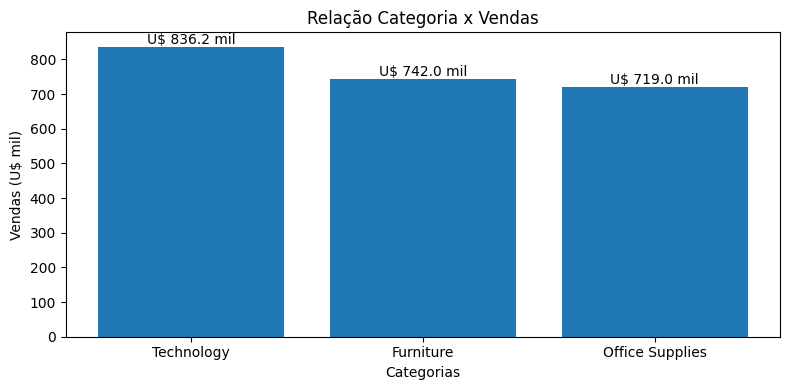

In [46]:
fig, ax = plt.subplots(figsize=(8, 4))

dados_categoria = dados_categoria.sort_values(
    by='vendas', ascending=False
)

bars = ax.bar(dados_categoria['categoria'],
              dados_categoria['vendas'] / 1000)

ax.set_xlabel('Categorias')
ax.set_ylabel('Vendas (U$ mil)')
ax.set_title('Relação Categoria x Vendas')
ax.bar_label(bars, fmt=lambda x: f'U$ {x:.1f} mil')

plt.tight_layout()
plt.show()

In [26]:
# Código aqui para saída ser igual mostrado abaixo

In [27]:
# Código aqui para saída ser igual mostrado abaixo

## Pergunta 3: Qual região vende mais e qual tem a melhor margem de lucro?
**Margem de lucro** = lucro ÷ vendas × 100

Pergunta 3 = 4 pontos

In [53]:
dados_regiao = df.groupby('regiao')[['vendas', 'lucro']].sum().reset_index()

In [54]:
dados_regiao['margem_lucro'] = (
    dados_regiao['lucro'] / dados_regiao['vendas'] * 100
)

In [55]:
dados_regiao.sort_values(by='vendas', ascending=False)

,regiao,vendas,lucro,margem_lucro
3,West,725457.8245,108418.4489,14.944831
1,East,678781.2400,91522.7800,13.483399
0,Central,501239.8908,39706.3625,7.921629
2,South,391721.9050,46749.4303,11.934342


In [28]:
# Código aqui para saída ser igual mostrado abaixo

Mostre o gráfico da quantidade de vendas
- Formate os valores em mil. Ex.: `U$ 72.0 mil`, `U$ 15.0 mil`

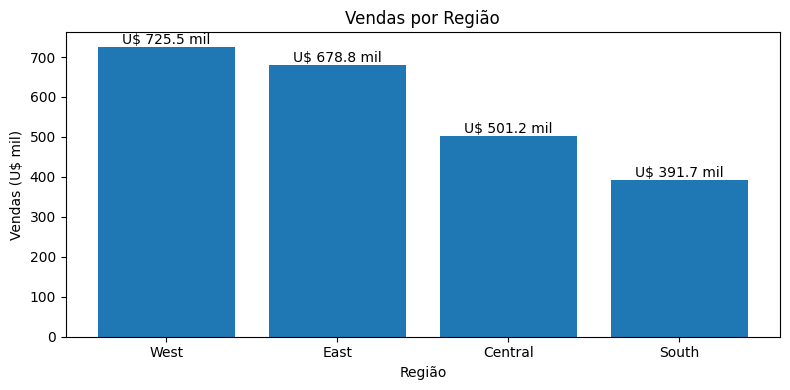

In [56]:
ig, ax = plt.subplots(figsize=(8, 4))

dados_regiao = dados_regiao.sort_values(by='vendas', ascending=False)

bars = ax.bar(dados_regiao['regiao'], dados_regiao['vendas'] / 1000)

ax.set_xlabel('Região')
ax.set_ylabel('Vendas (U$ mil)')
ax.set_title('Vendas por Região')
ax.bar_label(bars, fmt=lambda x: f'U$ {x:.1f} mil')

plt.tight_layout()
plt.show()

In [29]:
# Código aqui para saída ser igual mostrado abaixo

Mostre o gráfico do lucro
- Formate os valores em porcentagem com 1 casa decimal. Ex.: `10.5%`, `25.78%`

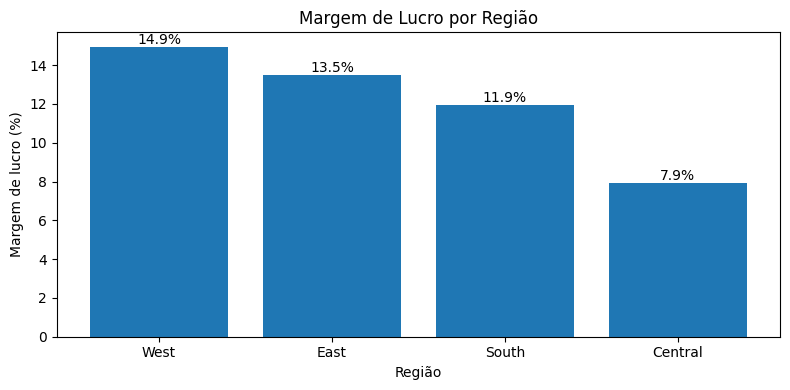

In [57]:
fig, ax = plt.subplots(figsize=(8, 4))

dados_margem = dados_regiao.sort_values(
    by='margem_lucro', ascending=False
)

bars = ax.bar(dados_margem['regiao'],
              dados_margem['margem_lucro'])

ax.set_xlabel('Região')
ax.set_ylabel('Margem de lucro (%)')
ax.set_title('Margem de Lucro por Região')
ax.bar_label(bars, fmt=lambda x: f'{x:.1f}%')

plt.tight_layout()
plt.show()

In [30]:
# Código aqui para saída ser igual mostrado abaixo

## Pergunta 4: Como foram as vendas ao longo dos anos?
- Demonstre o quantitativo de vendas e o percentual de cada ano.
- Formate as vendas em mil e com 2 casas decimais. Ex.: `U$ 130.35 mil`
- Formate o percentual em 1 casa decimal. Ex.: `12.1%`

Pergunta 4 = 5 pontos

In [58]:
dados_ano = df.groupby('ano')['vendas'].sum().reset_index()

In [59]:
dados_ano['porcentagem'] = (
    dados_ano['vendas'] / total_vendas * 100
)

In [60]:
dados_ano = dados_ano.sort_values(by='ano')

In [61]:
resultado_ano = dados_ano.copy()
resultado_ano['vendas'] = resultado_ano['vendas'].apply(
    lambda x: f'U$ {x / 1000:.2f} mil'
)
resultado_ano['porcentagem'] = resultado_ano['porcentagem'].apply(
    lambda x: f'{x:.1f}%'
)

resultado_ano

,ano,vendas,porcentagem
0,2014,U$ 484.25 mil,21.1%
1,2015,U$ 470.53 mil,20.5%
2,2016,U$ 609.21 mil,26.5%
3,2017,U$ 733.22 mil,31.9%


In [31]:
# Código aqui para saída ser igual mostrado abaixo

Mostre o gráfico de Vendas (U$) x Ano

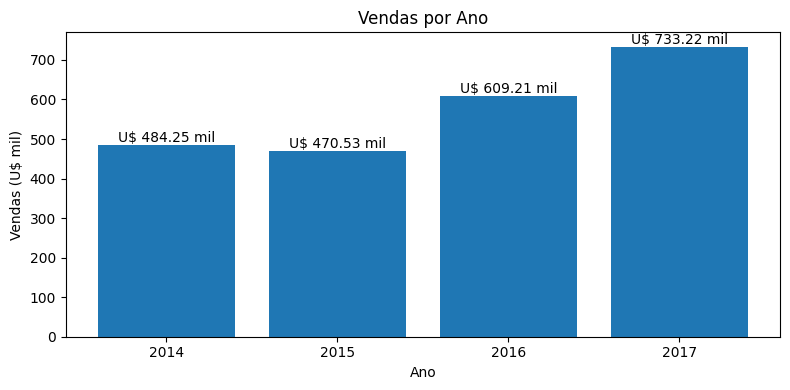

In [62]:
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(dados_ano['ano'], dados_ano['vendas'] / 1000)

ax.set_xlabel('Ano')
ax.set_ylabel('Vendas (U$ mil)')
ax.set_title('Vendas por Ano')
ax.bar_label(bars, fmt=lambda x: f'U$ {x:.2f} mil')

plt.tight_layout()
plt.show()

In [32]:
# Código aqui para saída ser igual mostrado abaixo

## Pergunta 5: Qual a porcentagem de pedidos com lucro e com prejuízo?

Pergunta 5 = 3 pontos

In [63]:
dados_situacao = df.groupby('situacao').size().reset_index(name='quantidade')

In [64]:
dados_situacao['porcentagem'] = (
    dados_situacao['quantidade'] / len(df) * 100
)

dados_situacao

,situacao,quantidade,porcentagem
0,Lucro,8058,80.628377
1,Prejuízo,1936,19.371623


In [33]:
# Código aqui para saída ser igual mostrado abaixo

Mostre o gráfico

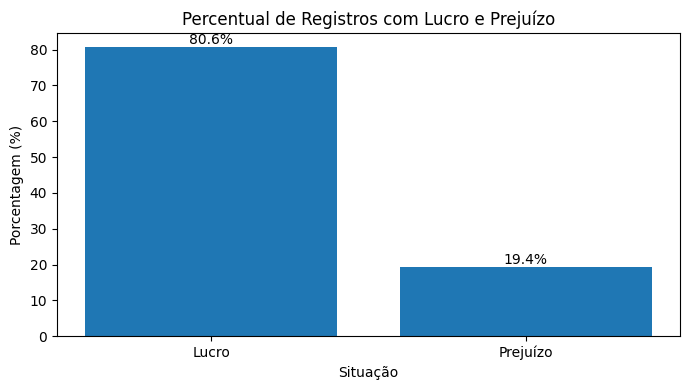

In [65]:
fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    dados_situacao['situacao'],
    dados_situacao['porcentagem']
)

ax.set_xlabel('Situação')
ax.set_ylabel('Porcentagem (%)')
ax.set_title('Percentual de Registros com Lucro e Prejuízo')
ax.bar_label(bars, fmt=lambda x: f'{x:.1f}%')

plt.tight_layout()
plt.show()

In [34]:
# Código aqui para saída ser igual mostrado abaixo

## Pergunta 6: O desconto atrapalha o lucro? (`mean`)
- Use o lucro médio de cada faixa de desconto
- Use as faixas de desconto
1. Sem desconto: 0.00
2. Até 20%
3. Acima de 20%

Pergunta 6 = 4 pontos

In [66]:
dados_desconto = df.groupby(
    'faixa_desconto'
)['lucro'].mean().reset_index()

print(dados_desconto)

  faixa_desconto      lucro
0   Acima de 20% -97.183098
1        Até 20%  26.501571
2   Sem desconto  66.900292


In [35]:
# Código aqui para saída ser igual mostrado abaixo

Mostre o gráfico

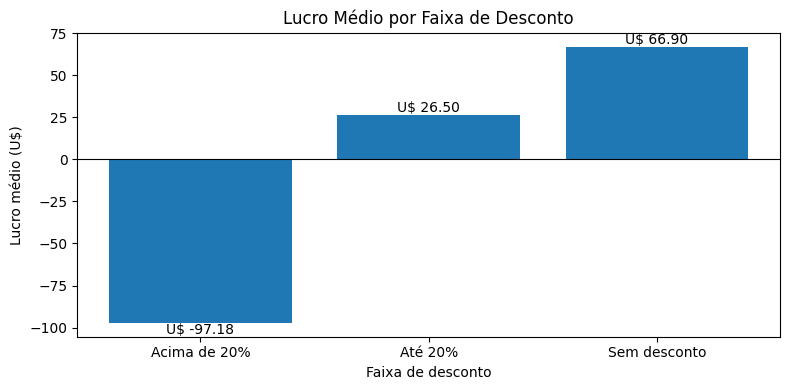

In [67]:
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    dados_desconto['faixa_desconto'].astype(str),
    dados_desconto['lucro']
)

ax.set_xlabel('Faixa de desconto')
ax.set_ylabel('Lucro médio (U$)')
ax.set_title('Lucro Médio por Faixa de Desconto')
ax.axhline(y=0, color='black', linewidth=0.8)
ax.bar_label(bars, fmt=lambda x: f'U$ {x:.2f}')

plt.tight_layout()
plt.show()

In [36]:
# Código aqui para saída ser igual mostrado abaixo

## Pergunta 7: Quais subcategorias dão mais lucro? E quais dão prejuízo?

Pergunta 7 = 4 pontos

In [37]:
# Código aqui para saída ser igual mostrado abaixo

In [38]:
# Código aqui para saída ser igual mostrado abaixo

## Pergunta 8: Qual segmento de cliente tem o maior valor médio por venda?

Pergunta 8 = 3 pontos

In [39]:
# Código aqui para saída ser igual mostrado abaixo

In [40]:
# Código aqui para saída ser igual mostrado abaixo

---
## Resumo das fórmulas
| Cálculo | Como fazer |
|---|---|
| Soma | `.groupby('col')['valor'].sum()` |
| Média | `.groupby('col')['valor'].mean()` |
| Contagem | `.groupby('col').size()` |
| Porcentagem | `parte / total * 100` |
| Margem de lucro | `lucro / vendas * 100` |